# ReviewLens GPT — 03 · Eksperimen lanjutan: jumlah epoch dan batch size

## Pertanyaan

Notebook 02 (6 epoch, batch 64) memilih **E2_lr_tinggi** (konfigurasi model default, lr 1e-3) sebagai model terbaik.
Notebook ini menjawab dua pertanyaan lanjutan:

1. Apakah melatih konfigurasi E2 **lebih lama (20 epoch)** memberi hasil lebih baik, atau justru overfitting?
2. Bagaimana pengaruh **batch size** (128 vs 64) terhadap hasil E2?

| Eksperimen | Model | lr | Epoch | Batch | Keterangan |
|---|---|---|---|---|---|
| E2_lr_tinggi | default | 1e-3 | 6 | 64 | **tidak dilatih ulang**; angka disalin dari output notebook 02 di Kaggle |
| E4_20epoch | default | 1e-3 | 20 | 64 | jumlah epoch |
| E5_batch128 | default | 1e-3 | 6 | 128 | batch size |

## Catatan desain (penting untuk membaca hasil)

- Kode data, vocabulary, dataset, fungsi training, checkpoint, dan evaluasi **dipakai ulang dari notebook 02**.
  Yang berubah hanya: epoch dan batch size per eksperimen, DataLoader train dibuat sesuai batch size eksperimen,
  dan output disimpan di `WORK_DIR/runs_lanjutan/`.
- Pipeline data deterministik (seed 42), sehingga split dan vocabulary sama dengan notebook 02.
- **E4 bukan "E2 yang dilanjutkan".** Learning rate memakai warmup 200 step lalu cosine decay sampai akhir training,
  jadi pada E4 decay direntangkan ke 20 epoch: LR di epoch 1–6 E4 lebih tinggi daripada E2 di epoch yang sama.
  Membandingkan epoch 6 E4 dengan epoch 6 E2 bukan perbandingan "jumlah epoch saja".
- **E5 memakai lr dan warmup yang sama** (tidak diskalakan terhadap batch size). Dengan batch 128, jumlah update
  per epoch setengah dari E2, sehingga perbedaan hasil mencampur efek batch size dan efek jumlah update.
- Val dan test loader tetap batch 64 (seperti notebook 02). Loss dihitung per token, jadi tidak bergantung batch size.
- Pembanding evaluasi tetap **silver label**, bukan anotasi manusia.

## Cara menjalankan di Kaggle

GPU T4 + Internet ON, *Add Input* dataset `Processed Dataset.csv`, *Run All*, lalu **Save Version**
(Save & Run All) atau unduh isi `/kaggle/working/runs_lanjutan/`.
Mode uji cepat `RL_QUICK=1` hanya untuk uji lokal; angkanya **bukan hasil eksperimen**.

## Bagian 0 — Konfigurasi

Sama seperti notebook 02 (deteksi Kaggle, `RL_WORK_DIR`/`RL_INPUT_DIR`, `RL_QUICK`), dengan perbedaan:

- Epoch dan batch size ditentukan **per eksperimen** (tidak ada `EPOCHS`/`BATCH_SIZE` global untuk training).
- `EVAL_BATCH_SIZE = 64` untuk val/test (sama dengan notebook 02).
- `RL_QUICK=1`: E4 4 epoch, E5 2 epoch, train di-subset 1.500 contoh, `N_EVAL=60`, warmup 20 step.
- `RUNS_DIR = WORK_DIR/runs_lanjutan`.
- `E2_REFERENCE` berisi angka E2 yang **disalin dari output notebook 02 di Kaggle** (bukan dihitung di sini).

In [1]:
import json
import math
import os
import platform
import random
import shutil
import subprocess
import sys
import time
from dataclasses import asdict
from pathlib import Path

ON_KAGGLE = Path("/kaggle/working").is_dir()
if ON_KAGGLE:
    WORK_DIR = Path("/kaggle/working")
    INPUT_DIR = Path("/kaggle/input")
else:
    missing_env = [k for k in ("RL_WORK_DIR", "RL_INPUT_DIR") if not os.environ.get(k)]
    if missing_env:
        raise RuntimeError(
            f"Bukan di Kaggle dan environment variable {missing_env} belum diisi. "
            "Contoh: RL_WORK_DIR=/tmp/rl_work RL_INPUT_DIR=/tmp/rl_input"
        )
    WORK_DIR = Path(os.environ["RL_WORK_DIR"])
    INPUT_DIR = Path(os.environ["RL_INPUT_DIR"])
WORK_DIR = WORK_DIR.resolve()
INPUT_DIR = INPUT_DIR.resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)

QUICK_TEST = os.environ.get("RL_QUICK", "0") == "1"

SEED = 42
EVAL_BATCH_SIZE = 64                           # val/test loader, sama dengan notebook 02
TRAIN_SUBSET = 1500 if QUICK_TEST else None    # None = seluruh train
N_EVAL = 60 if QUICK_TEST else 500             # contoh test untuk metrik berbasis generate
WARMUP_STEPS = 20 if QUICK_TEST else 200
MIN_LR_RATIO = 0.1                             # cosine decay sampai 10% LR awal
RESUME = True                                  # lanjutkan dari last.pt jika ada (lihat Bagian 6)

EXPERIMENTS = [   # konfigurasi model default + lr 1e-3 (seperti E2)
    {"name": "E4_20epoch",  "model": {}, "lr": 1e-3, "epochs": 4 if QUICK_TEST else 20, "batch_size": 64},
    {"name": "E5_batch128", "model": {}, "lr": 1e-3, "epochs": 2 if QUICK_TEST else 6,  "batch_size": 128},
]

# Disalin dari output notebook 02 di Kaggle (GPU T4, dataset asli, 6 epoch, batch 64). Tidak dihitung ulang.
E2_REFERENCE = {
    "name": "E2_lr_tinggi",
    "source": "disalin dari output notebook 02 di Kaggle",
    "model": {}, "lr": 1e-3, "epochs": 6, "batch_size": 64,
    "val_loss": [2.6266, 2.4936, 2.4295, 2.3966, 2.3774, 2.3741],   # epoch 1..6
    "best_val_loss": 2.3741,
    "eval": {
        "test_perplexity": 10.991,
        "format_validity": 1.000,
        "aspect_f1": {"positives": 0.927, "pain_points": 0.772, "suggestions": 0.774, "micro": 0.875},
        "exact_match": 0.800,
    },
}

# RL_REPO_URL hanya untuk uji lokal/offline (mis. path repo lokal); di Kaggle pakai default GitHub.
REPO_URL = os.environ.get("RL_REPO_URL", "https://github.com/nidahijriaa/reviewlens-mini-gpt.git")
BRANCH = "main"
REPO_DIR = WORK_DIR / "reviewlens-mini-gpt"
DATA_DIR = WORK_DIR / "data" / "processed"
RUNS_DIR = WORK_DIR / "runs_lanjutan"
CHILD_ENV = {**os.environ, "PYTHONIOENCODING": "utf-8"}   # ulasan bisa berisi emoji
os.environ["PYTHONIOENCODING"] = "utf-8"

print(f"Lingkungan  : {'Kaggle' if ON_KAGGLE else 'lokal'}")
print(f"Mode        : {'QUICK_TEST (bukan hasil eksperimen)' if QUICK_TEST else 'penuh'}")
print(f"WORK_DIR    : {WORK_DIR}")
print(f"INPUT_DIR   : {INPUT_DIR}")
print(f"RUNS_DIR    : {RUNS_DIR}")
print(f"SEED={SEED}  N_EVAL={N_EVAL}  TRAIN_SUBSET={TRAIN_SUBSET}  WARMUP_STEPS={WARMUP_STEPS}  "
      f"EVAL_BATCH_SIZE={EVAL_BATCH_SIZE}")
for exp in EXPERIMENTS:
    print(f"  {exp['name']:12s} lr={exp['lr']:.0e}  epochs={exp['epochs']:2d}  batch_size={exp['batch_size']}  "
          f"model={exp['model'] or 'default config.py'}")
print(f"  {E2_REFERENCE['name']:12s} (referensi, {E2_REFERENCE['source']}): best val loss {E2_REFERENCE['best_val_loss']}")

CHECKS = {}


def check(name, ok, detail=""):
    """Pemeriksaan keras: dicatat ke CHECKS dan dirangkum di Bagian 12."""
    CHECKS[name] = bool(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f" -- {detail}" if detail else ""))
    if not ok:
        raise AssertionError(f"Pemeriksaan gagal: {name} {detail}")

Lingkungan  : Kaggle
Mode        : penuh
WORK_DIR    : /kaggle/working
INPUT_DIR   : /kaggle/input
RUNS_DIR    : /kaggle/working/runs_lanjutan
SEED=42  N_EVAL=500  TRAIN_SUBSET=None  WARMUP_STEPS=200  EVAL_BATCH_SIZE=64
  E4_20epoch   lr=1e-03  epochs=20  batch_size=64  model=default config.py
  E5_batch128  lr=1e-03  epochs= 6  batch_size=128  model=default config.py
  E2_lr_tinggi (referensi, disalin dari output notebook 02 di Kaggle): best val loss 2.3741


## Bagian 1 — Source code (branch `main`)

Sama dengan notebook 02: clone atau perbarui secara aman (berhenti jika ada perubahan lokal), catat commit, tambahkan
`src/` ke `sys.path`, tampilkan device.

In [2]:
def run_git(*args, cwd=None):
    res = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(f"`git {' '.join(args)}` gagal (exit {res.returncode}):\n{res.stderr.strip()}")
    return res.stdout.strip()


def _norm_url(url):
    url = str(url).strip().rstrip("/")
    return url[:-4] if url.endswith(".git") else url


if shutil.which("git") is None:
    raise RuntimeError("Perintah `git` tidak tersedia.")

if not REPO_DIR.exists():
    print(f"Clone {REPO_URL} (branch {BRANCH}) -> {REPO_DIR}")
    try:
        run_git("clone", "--branch", BRANCH, "--single-branch", REPO_URL, str(REPO_DIR))
    except RuntimeError as exc:
        raise RuntimeError("Clone gagal. Di Kaggle pastikan Internet ON di Settings.\n" + str(exc)) from exc
else:
    print(f"Repository sudah ada di {REPO_DIR}; memeriksa sebelum memperbarui.")
    if not (REPO_DIR / ".git").is_dir():
        raise RuntimeError(f"{REPO_DIR} ada tetapi bukan repository git. Periksa/hapus manual.")
    origin = run_git("remote", "get-url", "origin", cwd=REPO_DIR)
    if _norm_url(origin) != _norm_url(REPO_URL):
        raise RuntimeError(f"origin = {origin!r}, bukan {REPO_URL!r}. Tidak diperbarui otomatis.")
    dirty = run_git("status", "--porcelain", cwd=REPO_DIR)
    if dirty:
        raise RuntimeError("Ada perubahan lokal di repository; tidak ditimpa otomatis:\n" + dirty)
    run_git("fetch", "origin", BRANCH, cwd=REPO_DIR)
    run_git("checkout", "-B", BRANCH, f"origin/{BRANCH}", cwd=REPO_DIR)

REPO_COMMIT = run_git("rev-parse", "HEAD", cwd=REPO_DIR)
print("Commit :", run_git("log", "-1", "--format=%H%n         %s (%ci)", cwd=REPO_DIR))

for d in (DATA_DIR, RUNS_DIR):
    if REPO_DIR.resolve() in d.resolve().parents:
        raise RuntimeError(f"{d} tidak boleh berada di dalam repository.")

SRC_DIR = REPO_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
for name in [m for m in sys.modules if m == "reviewlens" or m.startswith("reviewlens.")]:
    del sys.modules[name]

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

import reviewlens
from reviewlens.config import IGNORE_INDEX, ModelConfig, Paths, TrainConfig, get_device, set_seed
from reviewlens.dataset import (MAX_NEW_TOKENS, MAX_REVIEW_TOKENS, ReviewInsightDataset,
                                collate_fn, format_prompt, format_target)
from reviewlens.labeling import ASPECTS, InsightLabel, label_review
from reviewlens.model import MiniGPT
from reviewlens.preprocess import clean_text
from reviewlens.tokenizer import EOS, NEG, NONE, PAD, POS, SUG, UNK, SPECIAL_TOKENS, WordTokenizer

check("reviewlens di-import dari repo hasil clone",
      Path(reviewlens.__file__).resolve().parent == (SRC_DIR / "reviewlens").resolve(),
      reviewlens.__file__)

DEVICE = get_device()
print("\nPython :", platform.python_version(), "| torch", torch.__version__, "| pandas", pd.__version__)
print("Device :", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.startswith("cuda") else "")
if ON_KAGGLE and not DEVICE.startswith("cuda") and not QUICK_TEST:
    print("PERINGATAN: GPU tidak aktif. Aktifkan Accelerator GPU T4 agar training tidak sangat lambat.")

Clone https://github.com/nidahijriaa/reviewlens-mini-gpt.git (branch main) -> /kaggle/working/reviewlens-mini-gpt
Commit : a90ab6c0f12b1acbdfb0c96eedd0aeb089dd60f4
         Merge pull request #11 from nidahijriaa/docs/update-interfaces-grouped-split (2026-11-11 12:12:52 +0700)
[PASS] reviewlens di-import dari repo hasil clone -- /kaggle/working/reviewlens-mini-gpt/src/reviewlens/__init__.py

Python : 3.13.16 | torch 2.11.0+cu130 | pandas 2.3.3
Device : cuda (Tesla T4)


## Bagian 2 — Menemukan dataset

Sama dengan notebook 02: `rglob` di bawah `INPUT_DIR`; 0 kandidat → petunjuk *Add Input*; > 1 kandidat →
isi `CSV_PATH_OVERRIDE`. Hash SHA-256 dicek lagi di akhir.

In [3]:
import hashlib

CSV_NAME = "Processed Dataset.csv"
CSV_PATH_OVERRIDE = None   # isi HANYA jika ada lebih dari satu kandidat
ADD_INPUT_HELP = (f"Tambahkan dataset berisi '{CSV_NAME}' lewat panel kanan Kaggle: "
                  "Add Input -> pilih dataset -> Add, lalu jalankan ulang sel ini.")

if not INPUT_DIR.is_dir():
    raise FileNotFoundError(f"{INPUT_DIR} tidak ditemukan. {ADD_INPUT_HELP}")
candidates = sorted(p for p in INPUT_DIR.rglob(CSV_NAME) if p.is_file())
print(f"Kandidat '{CSV_NAME}' di bawah {INPUT_DIR}: {len(candidates)}")
for i, p in enumerate(candidates, 1):
    print(f"  [{i}] {p}  ({p.stat().st_size / 1e6:.2f} MB)")

if CSV_PATH_OVERRIDE is not None:
    CSV_PATH = Path(CSV_PATH_OVERRIDE)
    if CSV_PATH.resolve() not in {p.resolve() for p in candidates}:
        raise ValueError(f"CSV_PATH_OVERRIDE = {CSV_PATH} bukan salah satu kandidat di atas.")
elif not candidates:
    raise FileNotFoundError(f"File '{CSV_NAME}' tidak ditemukan di bawah {INPUT_DIR}. {ADD_INPUT_HELP}")
elif len(candidates) > 1:
    raise RuntimeError(f"Ditemukan {len(candidates)} file '{CSV_NAME}'. Isi CSV_PATH_OVERRIDE dengan "
                       "salah satu path di atas, lalu jalankan ulang sel ini.")
else:
    CSV_PATH = candidates[0]
print("Dataset:", CSV_PATH)


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


CSV_SHA256_BEFORE = sha256_file(CSV_PATH)
print("SHA-256:", CSV_SHA256_BEFORE)

Kandidat 'Processed Dataset.csv' di bawah /kaggle/input: 1
  [1] /kaggle/input/datasets/najwakhasanah/customer-review-indonesia/Processed Dataset.csv  (7.07 MB)
Dataset: /kaggle/input/datasets/najwakhasanah/customer-review-indonesia/Processed Dataset.csv
SHA-256: ba7efc3e98f0219de24ae1804f335f4d67bca0ac5fe7fd3e9ddc620bc6e84a21


## Bagian 3 — Preprocessing, grouped split, silver label

Sama dengan notebook 02 (`scripts/prepare_data.py`, default 80/10/10, seed 42). Hasilnya deterministik, sehingga
`train/val/test.jsonl` identik dengan yang dipakai notebook 02 untuk dataset yang sama.

In [4]:
def read_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]


PATHS = Paths(raw_csv=CSV_PATH, data_dir=DATA_DIR, checkpoint_dir=RUNS_DIR)
SPLIT_FILES = {"train": PATHS.train_jsonl, "val": PATHS.val_jsonl, "test": PATHS.test_jsonl}
DATA_DIR.mkdir(parents=True, exist_ok=True)
for p in [*SPLIT_FILES.values(), PATHS.vocab]:
    if p.exists():
        print("Hapus output lama:", p)
        p.unlink()

cmd = [sys.executable, str(REPO_DIR / "scripts" / "prepare_data.py"),
       "--csv", str(CSV_PATH), "--out-dir", str(DATA_DIR)]
t0 = time.time()
res = subprocess.run(cmd, cwd=REPO_DIR, capture_output=True, text=True, encoding="utf-8", env=CHILD_ENV)
(WORK_DIR / "prepare_data_stdout.txt").write_text(res.stdout + res.stderr, encoding="utf-8")
print(res.stdout)
if res.returncode != 0:
    raise RuntimeError(f"prepare_data.py gagal (exit {res.returncode}):\n{res.stderr}")
print(f"Selesai dalam {time.time() - t0:.1f} detik")

RECORDS = {s: read_jsonl(p) for s, p in SPLIT_FILES.items()}
SPLIT_COUNTS = {s: len(r) for s, r in RECORDS.items()}
print("\nJumlah record JSONL (train sudah di-oversample):")
split_table = pd.DataFrame({
    s: pd.Series([r["sentiment"] for r in recs]).value_counts() for s, recs in RECORDS.items()
}).fillna(0).astype(int).T
split_table["total"] = split_table.sum(axis=1)
display(split_table)
check("ketiga split tidak kosong", all(SPLIT_COUNTS.values()), str(SPLIT_COUNTS))

CSV        : /kaggle/input/datasets/najwakhasanah/customer-review-indonesia/Processed Dataset.csv
Output dir : /kaggle/working/data/processed
Loaded 41055 reviews, 0 empty after clean_text -> 41055 enter the split (before conflict removal)
Grouped split (seed=42, val=0.1, test=0.1):
  n_rows_input      : 41055
  n_groups          : 36189
  n_conflict_groups : 118
  n_rows_dropped    : 1845  (conflicting sentiment, removed)
  n_rows_kept       : 39210  (used for train/val/test)
  split_rows        : {'train': 31368, 'val': 3921, 'test': 3921}
  split_frac        : train 0.8000, val 0.1000, test 0.1000
  conflict_examples : 10 shown of 118
    - 'alhamdulillah berfungsi normal'
    - 'bagus kok'
    - 'barang cepat sampai'
    - 'barang good'
    - 'barang mendarat dengan selamat'
    - 'barang nya oke'
    - 'barang oke'
    - 'barang oke good'
    - 'barang oke mantap'
    - 'barang oke packing rapi'
Written (train oversampled x1.5 negatives): {'train': 34708, 'val': 3921, 'test': 3921

,positive,negative,neutral,total
train,21776,10019,2913,34708
val,2722,835,364,3921
test,2722,835,364,3921


[PASS] ketiga split tidak kosong -- {'train': 34708, 'val': 3921, 'test': 3921}


## Bagian 4 — Vocabulary (hanya dari train)

Sama dengan notebook 02: `python -m reviewlens.tokenizer` hanya membaca `train.jsonl`. `vocab_size` seharusnya sama
dengan notebook 02; nilainya dicatat di `comparison.json` untuk dicek.

In [5]:
tok_env = {**CHILD_ENV, "PYTHONPATH": str(SRC_DIR) + os.pathsep + CHILD_ENV.get("PYTHONPATH", "")}
res = subprocess.run([sys.executable, "-m", "reviewlens.tokenizer", "--data-dir", str(DATA_DIR)],
                     cwd=REPO_DIR, capture_output=True, text=True, encoding="utf-8", env=tok_env)
print(res.stdout)
if res.returncode != 0:
    raise RuntimeError(f"Pembangunan vocabulary gagal (exit {res.returncode}):\n{res.stderr}")

VOCAB_PATH = PATHS.vocab
tokenizer = WordTokenizer.load(VOCAB_PATH)
VOCAB_SIZE = tokenizer.vocab_size
check("ID token khusus 0-9 sesuai kontrak",
      tokenizer.encode(" ".join(SPECIAL_TOKENS)) == list(range(10)))

val_words = val_unk = 0
for r in RECORDS["val"]:
    ids = tokenizer.encode(r["review"])
    val_words += len(ids)
    val_unk += sum(i == UNK for i in ids)
UNK_VAL_PCT = 100 * val_unk / max(val_words, 1)
print(f"vocab_size                 : {VOCAB_SIZE:,}")
print(f"<unk> pada ulasan validation: {UNK_VAL_PCT:.2f}% ({val_unk:,} dari {val_words:,} kata)")

train records: 34708 (31329 unique used for counting)
vocab_size   : 5970 (min_freq=3, max_size=10000)
<unk> rate on train reviews: 5.74%
saved        : /kaggle/working/data/processed/vocab.json

[PASS] ID token khusus 0-9 sesuai kontrak
vocab_size                 : 5,970
<unk> pada ulasan validation: 6.83% (3,593 dari 52,581 kata)


## Bagian 5 — Dataset dan DataLoader

Sama dengan notebook 02, kecuali `make_loader` kini menerima `batch_size` (default `EVAL_BATCH_SIZE = 64` untuk
val/test). DataLoader train dibuat **di dalam** `train_experiment` dengan batch size eksperimen. Pemeriksaan
`PAD (0)` tidak pernah menjadi target tetap dijalankan.

In [6]:
BLOCK_SIZE = ModelConfig(vocab_size=VOCAB_SIZE).block_size
train_full = ReviewInsightDataset(PATHS.train_jsonl, tokenizer, BLOCK_SIZE)
val_ds = ReviewInsightDataset(PATHS.val_jsonl, tokenizer, BLOCK_SIZE)
test_ds = ReviewInsightDataset(PATHS.test_jsonl, tokenizer, BLOCK_SIZE)
if TRAIN_SUBSET is not None and TRAIN_SUBSET < len(train_full):
    subset_idx = np.random.default_rng(SEED).permutation(len(train_full))[:TRAIN_SUBSET]
    train_ds = Subset(train_full, sorted(subset_idx.tolist()))
else:
    train_ds = train_full
print(f"block_size={BLOCK_SIZE} | train {len(train_ds):,} (dari {len(train_full):,}) | "
      f"val {len(val_ds):,} | test {len(test_ds):,}")


def make_loader(ds, shuffle, epoch=0, batch_size=EVAL_BATCH_SIZE):
    """Shuffle deterministik per epoch: generator di-seed dengan SEED + epoch."""
    gen = torch.Generator().manual_seed(SEED + epoch) if shuffle else None
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=gen, collate_fn=collate_fn)


val_loader = make_loader(val_ds, shuffle=False)
test_loader = make_loader(test_ds, shuffle=False)

x, y = next(iter(make_loader(train_ds, shuffle=True, epoch=1)))
print(f"\nSatu batch: x {tuple(x.shape)} {x.dtype} | y {tuple(y.shape)} {y.dtype}")
print("x[0][:16] :", x[0][:16].tolist())
print("y[0][:16] :", y[0][:16].tolist())
print("\nDecode satu contoh sekuens:")
print(tokenizer.decode(train_ds[0]))

n_pad_target, n_ignore = 0, 0
for loader in (make_loader(train_full, shuffle=False), val_loader, test_loader):
    for xb, yb in loader:
        n_pad_target += int((yb == PAD).sum())
        n_ignore += int((yb == IGNORE_INDEX).sum())
        assert torch.all(xb[yb == IGNORE_INDEX] == PAD)
check("PAD (0) tidak pernah menjadi target (train/val/test)", n_pad_target == 0,
      f"posisi y==PAD: {n_pad_target}, posisi y==IGNORE_INDEX: {n_ignore:,}")
check("x.shape == y.shape dan T <= block_size", x.shape == y.shape and x.shape[1] <= BLOCK_SIZE)

block_size=128 | train 34,708 (dari 34,708) | val 3,921 | test 3,921

Satu batch: x (64, 60) torch.int64 | y (64, 60) torch.int64
x[0][:16] : [2, 4, 78, 26, 110, 5, 9, 6, 64, 39, 40, 19, 20, 7, 33, 11]
y[0][:16] : [4, 78, 26, 110, 5, 9, 6, 64, 39, 40, 19, 20, 7, 33, 11, 65]

Decode satu contoh sekuens:
<bos> <review> barang mendarat dengan selamat di <unk> kota layar tidak pecah remot berfungsi sambungan <unk> k hp baik overall baik semoga awet <pos> kualitas produk bagus <sep> produk berfungsi dengan baik <neg> <none> <sug> <none> <eos>
[PASS] PAD (0) tidak pernah menjadi target (train/val/test) -- posisi y==PAD: 0, posisi y==IGNORE_INDEX: 2,501,489
[PASS] x.shape == y.shape dan T <= block_size


## Bagian 6 — Fungsi training

Sama dengan notebook 02 (`lr_at`, `estimate_loss` per token, AdamW (0.9, 0.95) dengan weight decay hanya untuk
parameter dim ≥ 2, gradient clipping 1.0, shuffle `SEED + epoch`, checkpoint 7 kunci atomik, resume dari `last.pt`).
Perbedaan: `TrainConfig` memakai `epochs` dan `batch_size` milik eksperimen, dan DataLoader train dibuat dengan
batch size tersebut. Jadwal LR dihitung dari total step eksperimen itu sendiri
(`ceil(n_train / batch_size) × epochs`).

In [7]:
CKPT_KEYS = ("model_state", "optimizer_state", "model_cfg", "epoch", "step", "best_val_loss", "vocab_path")


def lr_at(step, train_cfg, total_steps):
    """Warmup linear lalu cosine decay ke MIN_LR_RATIO * lr. step dimulai dari 0."""
    base = train_cfg.lr
    warmup = max(1, train_cfg.warmup_steps)
    if step < warmup:
        return base * (step + 1) / warmup
    progress = min(1.0, (step - warmup) / max(1, total_steps - warmup))
    return base * (MIN_LR_RATIO + (1 - MIN_LR_RATIO) * 0.5 * (1 + math.cos(math.pi * progress)))


@torch.no_grad()
def estimate_loss(model, loader, device, max_batches=None):
    """Rata-rata NLL per token valid (y != IGNORE_INDEX) atas seluruh loader."""
    was_training = model.training
    model.eval()
    total, count = 0.0, 0
    for i, (xb, yb) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        xb, yb = xb.to(device), yb.to(device)
        logits, _ = model(xb)
        total += F.cross_entropy(logits.view(-1, logits.size(-1)), yb.view(-1),
                                 ignore_index=IGNORE_INDEX, reduction="sum").item()
        count += int((yb != IGNORE_INDEX).sum())
    model.train(was_training)
    if count == 0:
        raise ValueError("loader tidak berisi token target yang valid")
    return total / count


def configure_optimizer(model, train_cfg):
    params = [p for p in model.parameters() if p.requires_grad]   # parameter tied dihitung sekali
    decay = [p for p in params if p.dim() >= 2]
    no_decay = [p for p in params if p.dim() < 2]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": train_cfg.weight_decay},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=train_cfg.lr, betas=(0.9, 0.95),
    )


def _atomic_replace(tmp, path):
    os.replace(tmp, path)


def save_checkpoint(path, model, optimizer, model_cfg, epoch, step, best_val_loss, vocab_path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "model_cfg": asdict(model_cfg),
        "epoch": int(epoch),
        "step": int(step),
        "best_val_loss": float(best_val_loss),
        "vocab_path": str(vocab_path),
    }, tmp)
    _atomic_replace(tmp, path)


def load_checkpoint(path, device):
    ckpt = torch.load(path, map_location=device, weights_only=True)
    missing = [k for k in CKPT_KEYS if k not in ckpt]
    if missing:
        raise ValueError(f"Checkpoint {path} tidak valid, kunci hilang: {missing}")
    return ckpt


def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8")
    _atomic_replace(tmp, path)


def train_experiment(exp):
    name = exp["name"]
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    run_vocab = run_dir / "vocab.json"
    if run_vocab.exists() and run_vocab.read_bytes() != VOCAB_PATH.read_bytes():
        raise ValueError(f"{run_vocab} berbeda dari vocabulary saat ini. Hapus {run_dir} atau set RESUME=False.")
    shutil.copy2(VOCAB_PATH, run_vocab)

    model_cfg = ModelConfig(vocab_size=VOCAB_SIZE, **exp["model"])
    train_cfg = TrainConfig(batch_size=exp["batch_size"], lr=exp["lr"], max_epochs=exp["epochs"],
                            warmup_steps=WARMUP_STEPS, seed=SEED, device=DEVICE)
    set_seed(train_cfg.seed)
    model = MiniGPT(model_cfg).to(DEVICE)
    optimizer = configure_optimizer(model, train_cfg)
    steps_per_epoch = math.ceil(len(train_ds) / train_cfg.batch_size)
    total_steps = steps_per_epoch * train_cfg.max_epochs

    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    hist_path, init_path = run_dir / "history.json", run_dir / "init.json"
    start_epoch, step, best_val, history = 1, 0, float("inf"), []
    if RESUME and last_path.exists():
        ckpt = load_checkpoint(last_path, DEVICE)
        if ckpt["model_cfg"] != asdict(model_cfg):
            raise ValueError(f"model_cfg di {last_path} berbeda dari eksperimen {name}. "
                             "Hapus folder run tersebut atau set RESUME=False.")
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        step, best_val, start_epoch = ckpt["step"], ckpt["best_val_loss"], ckpt["epoch"] + 1
        if hist_path.exists():
            history = [h for h in json.loads(hist_path.read_text(encoding="utf-8")) if h["epoch"] <= ckpt["epoch"]]
        print(f"[{name}] resume dari epoch {ckpt['epoch']} (step {step}, best val {best_val:.4f})")
        init = json.loads(init_path.read_text(encoding="utf-8")) if init_path.exists() else {}
    else:
        val0 = estimate_loss(model, val_loader, DEVICE)
        init = {"val_loss_epoch0": val0, "ln_vocab_size": math.log(VOCAB_SIZE)}
        write_json(init_path, init)
        print(f"[{name}] {model.num_parameters():,} parameter | epoch 0 (bobot acak): val loss {val0:.4f} "
              f"vs ln(vocab_size) = {math.log(VOCAB_SIZE):.4f} (selisih {val0 - math.log(VOCAB_SIZE):+.4f})")

    if start_epoch > train_cfg.max_epochs:
        print(f"[{name}] training sudah selesai ({train_cfg.max_epochs} epoch); dilewati.")
    for epoch in range(start_epoch, train_cfg.max_epochs + 1):
        model.train()
        t0 = time.time()
        loss_sum, tok_sum = 0.0, 0
        for xb, yb in make_loader(train_ds, shuffle=True, epoch=epoch, batch_size=train_cfg.batch_size):
            lr = lr_at(step, train_cfg, total_steps)
            for group in optimizer.param_groups:
                group["lr"] = lr
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            _, loss = model(xb, yb)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"[{name}] loss tidak finite pada step {step}: {loss.item()}")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), train_cfg.grad_clip)
            optimizer.step()
            step += 1
            n_tok = int((yb != IGNORE_INDEX).sum())
            loss_sum += loss.item() * n_tok
            tok_sum += n_tok
        train_loss = loss_sum / tok_sum
        val_loss = estimate_loss(model, val_loader, DEVICE)
        improved = val_loss < best_val
        if improved:
            best_val = val_loss
            save_checkpoint(best_path, model, optimizer, model_cfg, epoch, step, best_val, "vocab.json")
        save_checkpoint(last_path, model, optimizer, model_cfg, epoch, step, best_val, "vocab.json")
        seconds = time.time() - t0
        history.append({"epoch": epoch, "step": step, "train_loss": train_loss, "val_loss": val_loss,
                        "lr": lr, "seconds": seconds})
        write_json(hist_path, history)
        print(f"[{name}] epoch {epoch}/{train_cfg.max_epochs} | train {train_loss:.4f} | val {val_loss:.4f} "
              f"{'*best*' if improved else '      '} | lr {lr:.2e} | {seconds:.1f}s")

    result = {
        "name": name,
        "model_cfg": asdict(model_cfg),
        "lr": train_cfg.lr,
        "batch_size": train_cfg.batch_size,
        "total_steps": total_steps,
        "n_parameters": model.num_parameters(),
        "epochs": train_cfg.max_epochs,
        "steps_per_epoch": steps_per_epoch,
        "train_examples": len(train_ds),
        "val_loss_epoch0": init.get("val_loss_epoch0"),
        "ln_vocab_size": math.log(VOCAB_SIZE),
        "history": history,
        "final_train_loss": history[-1]["train_loss"],
        "best_val_loss": best_val,
        "best_epoch": min(history, key=lambda h: h["val_loss"])["epoch"],
        "val_perplexity": math.exp(best_val),
        "duration_seconds": sum(h["seconds"] for h in history),
        "run_dir": str(run_dir),
    }
    del model, optimizer
    if DEVICE.startswith("cuda"):
        torch.cuda.empty_cache()
    return result


# --- Uji cepat komponen sebelum training sungguhan ------------------------------
_cfg = TrainConfig(lr=1e-3, warmup_steps=10)
_lrs = [lr_at(s, _cfg, 100) for s in range(100)]
check("lr_at: warmup linear lalu cosine ke 10%",
      abs(_lrs[0] - 1e-4) < 1e-12 and abs(_lrs[9] - 1e-3) < 1e-12 and abs(lr_at(100, _cfg, 100) - 1e-4) < 1e-12
      and all(a >= b for a, b in zip(_lrs[9:], _lrs[10:])),
      f"lr[0]={_lrs[0]:.1e}, lr[9]={_lrs[9]:.1e}, lr[end]={lr_at(100, _cfg, 100):.1e}")

set_seed(SEED)
_m = MiniGPT(ModelConfig(vocab_size=VOCAB_SIZE, n_layer=1, d_model=32, n_head=2, d_ff=64)).to(DEVICE).eval()
_xb, _yb = next(iter(val_loader))
with torch.no_grad():
    _, _mean = _m(_xb.to(DEVICE), _yb.to(DEVICE))
check("estimate_loss = rata-rata per token (sama dengan mean CE pada 1 batch)",
      abs(estimate_loss(_m, val_loader, DEVICE, max_batches=1) - _mean.item()) < 1e-4)
_opt = configure_optimizer(_m, TrainConfig())
check("weight decay hanya untuk parameter dim >= 2",
      all(p.dim() >= 2 for p in _opt.param_groups[0]["params"])
      and all(p.dim() < 2 for p in _opt.param_groups[1]["params"])
      and _opt.param_groups[1]["weight_decay"] == 0.0 and _opt.defaults["betas"] == (0.9, 0.95))
del _m, _opt

[PASS] lr_at: warmup linear lalu cosine ke 10% -- lr[0]=1.0e-04, lr[9]=1.0e-03, lr[end]=1.0e-04
[PASS] estimate_loss = rata-rata per token (sama dengan mean CE pada 1 batch)
[PASS] weight decay hanya untuk parameter dim >= 2


## Bagian 7 — Menjalankan E4 dan E5

Kode sama dengan notebook 02. Setiap epoch mencetak train loss, val loss, tanda `*best*`, LR terakhir, dan waktu.
Eksperimen yang divergen dicatat sebagai gagal tanpa menghentikan notebook. Jika sesi Kaggle terputus, menjalankan
ulang notebook melanjutkan dari `runs_lanjutan/<nama>/last.pt`.

In [8]:
RESULTS, FAILED = [], []
for exp in EXPERIMENTS:
    print("=" * 96)
    try:
        RESULTS.append(train_experiment(exp))
    except FloatingPointError as exc:   # mis. divergen pada lr tinggi: catat, lanjut ke eksperimen berikutnya
        print(f"[{exp['name']}] GAGAL: {exc}")
        FAILED.append({"name": exp["name"], "error": str(exc)})
        if DEVICE.startswith("cuda"):
            torch.cuda.empty_cache()
print("=" * 96)
if not RESULTS:
    raise RuntimeError(f"Semua eksperimen gagal: {FAILED}")
if FAILED:
    print("Eksperimen gagal (tidak ikut perbandingan):", [f["name"] for f in FAILED])

for r in RESULTS:
    ckpt = load_checkpoint(Path(r["run_dir"]) / "best.pt", "cpu")
    check(f"{r['name']}: best.pt berisi 7 kunci wajib", set(ckpt) == set(CKPT_KEYS))
    gap = r["val_loss_epoch0"] - r["ln_vocab_size"] if r["val_loss_epoch0"] is not None else float("nan")
    print(f"    val loss epoch 0 = {r['val_loss_epoch0']:.4f}, ln(V) = {r['ln_vocab_size']:.4f}, selisih {gap:+.4f}")

[E4_20epoch] 4,720,640 parameter | epoch 0 (bobot acak): val loss 8.7398 vs ln(vocab_size) = 8.6945 (selisih +0.0453)
[E4_20epoch] epoch 1/20 | train 3.3684 | val 2.6305 *best* | lr 9.98e-04 | 33.0s
[E4_20epoch] epoch 2/20 | train 2.4956 | val 2.5025 *best* | lr 9.85e-04 | 34.4s
[E4_20epoch] epoch 3/20 | train 2.3836 | val 2.4509 *best* | lr 9.61e-04 | 35.4s
[E4_20epoch] epoch 4/20 | train 2.3113 | val 2.4313 *best* | lr 9.26e-04 | 36.1s
[E4_20epoch] epoch 5/20 | train 2.2510 | val 2.4123 *best* | lr 8.82e-04 | 35.8s
[E4_20epoch] epoch 6/20 | train 2.1971 | val 2.4025 *best* | lr 8.29e-04 | 35.9s
[E4_20epoch] epoch 7/20 | train 2.1443 | val 2.4065        | lr 7.70e-04 | 35.7s
[E4_20epoch] epoch 8/20 | train 2.0947 | val 2.4084        | lr 7.04e-04 | 35.6s
[E4_20epoch] epoch 9/20 | train 2.0421 | val 2.4147        | lr 6.35e-04 | 35.7s
[E4_20epoch] epoch 10/20 | train 1.9911 | val 2.4281        | lr 5.63e-04 | 35.7s
[E4_20epoch] epoch 11/20 | train 1.9382 | val 2.4426        | lr 4.92e-

## Bagian 8 — Evaluasi `best.pt` setiap eksperimen

Metrik sama dengan notebook 02 (kunci INTERFACES §11): `test_perplexity` pada seluruh test set; `format_validity`,
`aspect_f1` (positives, pain_points, suggestions, micro), dan `exact_match` pada `N_EVAL` contoh pertama test, dengan
greedy decoding. `parse_generation` disalin apa adanya dari notebook 02; `generate_insight` dan evaluasi dibuat
menerima model sebagai argumen agar bisa dipakai untuk beberapa checkpoint.

> Pembanding = **silver label** (`label_review`), bukan anotasi manusia.

In [9]:
MARKERS = ("<pos>", "<neg>", "<sug>", "<eos>")
SECTION_OF = {"<pos>": "positives", "<neg>": "pain_points", "<sug>": "suggestions"}
DROP_TOKENS = {"<none>", "<pad>", "<bos>", "<review>"}


def parse_generation(text):
    """-> (positives, pain_points, suggestions, valid_format). Toleran terhadap output rusak."""
    tokens = text.split()
    valid = [t for t in tokens if t in MARKERS] == list(MARKERS)
    out = {"positives": [], "pain_points": [], "suggestions": []}
    section, buf = None, []

    def flush():
        phrase = " ".join(t for t in buf if t not in DROP_TOKENS)
        if section is not None and phrase and phrase not in out[section]:
            out[section].append(phrase)
        buf.clear()

    for t in tokens:
        if t == "<eos>":
            break
        if t in SECTION_OF:
            flush()
            section = SECTION_OF[t]
        elif t == "<sep>":
            flush()
        else:
            buf.append(t)
    flush()
    return out["positives"], out["pain_points"], out["suggestions"], valid



def generate_insight(review, model, tok):
    review_clean = clean_text(review)
    if not review_clean:   # kosong setelah dibersihkan -> model tidak dipanggil
        return {"review": review, "review_clean": "", "positives": [], "pain_points": [],
                "suggestions": [], "raw_output": "", "valid_format": False}
    prompt_ids = tok.encode(format_prompt(review_clean))
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    out = model.generate(idx, max_new_tokens=MAX_NEW_TOKENS, temperature=0.0, eos_id=EOS)
    raw = tok.decode(out[0, len(prompt_ids) - 1:].tolist())   # mulai dari <pos> terakhir prompt
    pos, neg, sug, valid = parse_generation(raw)
    return {"review": review, "review_clean": review_clean, "positives": pos, "pain_points": neg,
            "suggestions": sug, "raw_output": raw, "valid_format": valid}


SECTIONS = ("positives", "pain_points", "suggestions")
LEXICON_PHRASES = {p for a in ASPECTS for p in (a.pos_phrase, a.neg_phrase, a.suggestion)}


def f1_from(tp, fp, fn):
    denom = 2 * tp + fp + fn
    return 1.0 if denom == 0 else 2 * tp / denom


def evaluate_run(result):
    """Muat best.pt satu eksperimen lalu hitung metrik INTERFACES §11."""
    run_dir = Path(result["run_dir"])
    ckpt_path = run_dir / "best.pt"
    ckpt = load_checkpoint(ckpt_path, DEVICE)
    tok = WordTokenizer.load(run_dir / ckpt["vocab_path"])
    check(f"{result['name']}: vocab salinan run == vocab training", tok == tokenizer)
    model = MiniGPT(ModelConfig(**ckpt["model_cfg"])).to(DEVICE)
    model.load_state_dict(ckpt["model_state"])
    model.eval()

    t0 = time.time()
    test_nll = estimate_loss(model, test_loader, DEVICE)
    eval_records = RECORDS["test"][:N_EVAL]
    counts = {s: {"tp": 0, "fp": 0, "fn": 0} for s in SECTIONS}
    n_valid = n_exact = n_out_of_lexicon = 0
    for rec in eval_records:
        g = generate_insight(rec["review"], model, tok)
        n_valid += g["valid_format"]
        exact = True
        for s in SECTIONS:
            pred, gold = set(g[s]), set(rec[s])
            counts[s]["tp"] += len(pred & gold)
            counts[s]["fp"] += len(pred - gold)
            counts[s]["fn"] += len(gold - pred)
            n_out_of_lexicon += len(pred - LEXICON_PHRASES)
            exact &= pred == gold
        n_exact += exact
    aspect_f1 = {s: f1_from(**counts[s]) for s in SECTIONS}
    aspect_f1["micro"] = f1_from(*(sum(counts[s][k] for s in SECTIONS) for k in ("tp", "fp", "fn")))
    ev = {
        "split": "test",
        "checkpoint": str(ckpt_path),
        "n_examples_perplexity": len(test_ds),
        "n_examples_generation": len(eval_records),
        "test_perplexity": math.exp(test_nll),
        "format_validity": n_valid / len(eval_records),
        "aspect_f1": aspect_f1,
        "exact_match": n_exact / len(eval_records),
    }
    check(f"{result['name']}: kunci eval sesuai INTERFACES §11",
          set(ev) == {"split", "checkpoint", "n_examples_perplexity", "n_examples_generation", "test_perplexity",
                      "format_validity", "aspect_f1", "exact_match"})
    write_json(run_dir / "eval.json", ev)
    print(f"[{result['name']}] best.pt epoch {ckpt['epoch']} | evaluasi {time.time() - t0:.1f}s | "
          f"ppl {ev['test_perplexity']:.3f} | validity {ev['format_validity']:.3f} | "
          f"micro F1 {aspect_f1['micro']:.3f} | exact {ev['exact_match']:.3f} | di luar lexicon {n_out_of_lexicon}")
    del model
    if DEVICE.startswith("cuda"):
        torch.cuda.empty_cache()
    return ev


check("parse_generation: format valid",
      parse_generation("<pos> a b <sep> a b <neg> <none> <sug> <none> <eos>") == (["a b"], [], [], True))
EVALS = {r["name"]: evaluate_run(r) for r in RESULTS}

[PASS] parse_generation: format valid
[PASS] E4_20epoch: vocab salinan run == vocab training
[PASS] E4_20epoch: kunci eval sesuai INTERFACES §11
[E4_20epoch] best.pt epoch 6 | evaluasi 19.2s | ppl 11.322 | validity 1.000 | micro F1 0.846 | exact 0.766 | di luar lexicon 123
[PASS] E5_batch128: vocab salinan run == vocab training
[PASS] E5_batch128: kunci eval sesuai INTERFACES §11
[E5_batch128] best.pt epoch 6 | evaluasi 18.6s | ppl 10.757 | validity 1.000 | micro F1 0.867 | exact 0.806 | di luar lexicon 118


## Bagian 9 — Perbandingan E2 vs E4 vs E5

- **Tabel val loss per epoch.** Kolom E2 **disalin dari output notebook 02 di Kaggle**; E4 dan E5 dari run ini.
- **Analisis E4 (20 epoch):** best epoch, val loss epoch terakhir, berapa epoch setelah best yang val loss-nya lebih
  tinggi dari best, dan selisih `val − train` di best epoch dan epoch terakhir. `train_loss` dihitung dengan dropout
  aktif, sehingga selisih ini sedikit meremehkan generalization gap sebenarnya.
- **Tabel metrik evaluasi** E2 (disalin) vs E4 vs E5 beserta selisih terhadap E2.
- **Grafik:** val loss E2 (referensi), E4, E5 dan train loss E4 → `runs_lanjutan/comparison.png`.

Interpretasi otomatis di bawah hanya mendeskripsikan angka; kesimpulan akhir tetap perlu dibaca bersama catatan desain
di awal notebook (jadwal LR E4 berbeda dari E2; E5 memiliki setengah jumlah update).

Val loss per epoch (E2 disalin dari output notebook 02 di Kaggle):


,"E2 (notebook 02, Kaggle)",E4_20epoch,E5_batch128
epoch,,,
1,2.6266,2.6305,2.7174
2,2.4936,2.5025,2.5027
3,2.4295,2.4509,2.4230
4,2.3966,2.4313,2.3871
5,2.3774,2.4123,2.3600
6,2.3741,2.4025,2.3548
7,NaN,2.4065,NaN
8,NaN,2.4084,NaN
9,NaN,2.4147,NaN



Analisis E4_20epoch:
  epochs_trained                      : 20
  best_epoch                          : 6
  best_val_loss                       : 2.4025
  last_epoch                          : 20
  last_val_loss                       : 2.6023
  last_minus_best_val                 : 0.1998
  epochs_after_best                   : 14
  epochs_after_best_with_higher_val   : 14
  gap_val_minus_train_best_epoch      : 0.2054
  gap_val_minus_train_last_epoch      : 1.0165
  best_vs_e2_best                     : 0.0284

  -> Val loss minimum di epoch 6, lalu 14 dari 14 epoch berikutnya lebih tinggi; epoch 20 naik +0.1998 (+8.32% dari best).
     Selisih val-train: +0.2054 (best epoch) -> +1.0165 (epoch terakhir) — melebar: indikasi overfitting setelah epoch 6.
     best.pt menyimpan epoch 6, bukan epoch terakhir. Besarnya kenaikan perlu dinilai bersama variasi antar-epoch, bukan dari tanda +/− saja.
  -> Best val loss E4 vs E2: +0.0284 (tidak lebih baik dari E2).

Metrik evaluasi (test; pemba

,"E2 (notebook 02, Kaggle)",E4_20epoch,E4_20epoch − E2,E5_batch128,E5_batch128 − E2
metrik,,,,,
test_perplexity,10.9910,11.3219,0.3309,10.7568,-0.2342
format_validity,1.0000,1.0000,0.0000,1.0000,0.0000
aspect_f1.positives,0.9270,0.9067,-0.0203,0.9216,-0.0054
aspect_f1.pain_points,0.7720,0.7340,-0.0380,0.7586,-0.0134
aspect_f1.suggestions,0.7740,0.7340,-0.0400,0.7550,-0.0190
aspect_f1.micro,0.8750,0.8459,-0.0291,0.8673,-0.0077
exact_match,0.8000,0.7660,-0.0340,0.8060,0.0060
best_val_loss,2.3741,2.4025,0.0284,2.3548,-0.0193


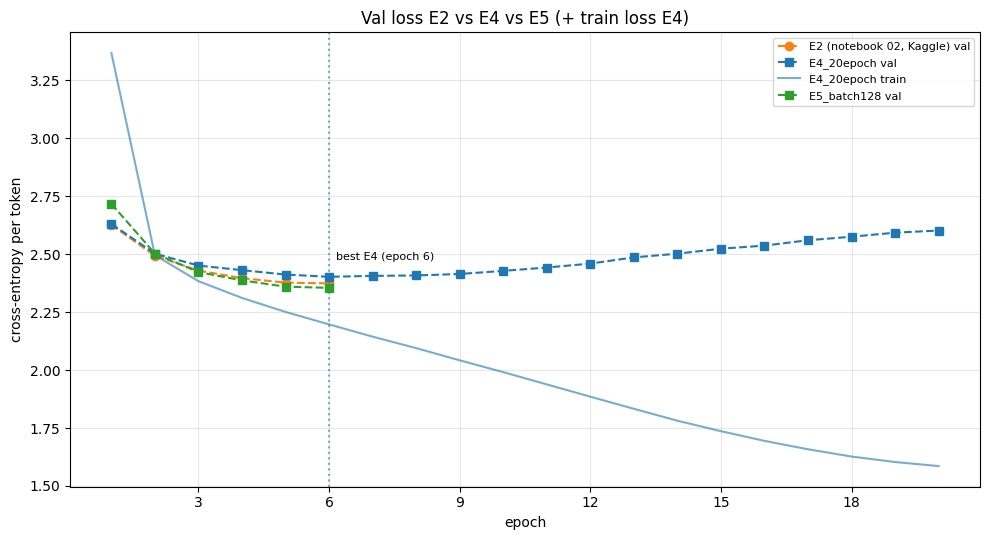

Disimpan: /kaggle/working/runs_lanjutan/comparison.png


In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

by_name = {r["name"]: r for r in RESULTS}
E2_LABEL = "E2 (notebook 02, Kaggle)"
if QUICK_TEST:
    print("PERINGATAN QUICK_TEST: E4/E5 dilatih pada data uji/subset dengan epoch dikurangi, sedangkan angka E2 berasal "
          "dari dataset asli. Semua selisih terhadap E2 di bawah TIDAK bermakna; bagian ini hanya menguji kode.\n")

# --- 1. Tabel val loss per epoch ---------------------------------------------------
series = {E2_LABEL: dict(enumerate(E2_REFERENCE["val_loss"], start=1))}
for r in RESULTS:
    series[r["name"]] = {h["epoch"]: h["val_loss"] for h in r["history"]}
max_epoch = max(max(s) for s in series.values())
VAL_TABLE = pd.DataFrame({k: [v.get(e) for e in range(1, max_epoch + 1)] for k, v in series.items()},
                         index=pd.RangeIndex(1, max_epoch + 1, name="epoch"))
print("Val loss per epoch (E2 disalin dari output notebook 02 di Kaggle):")
display(VAL_TABLE.round(4))

# --- 2. Analisis E4 ------------------------------------------------------------------
E4_ANALYSIS = None
if "E4_20epoch" in by_name:
    h = by_name["E4_20epoch"]["history"]
    best = min(h, key=lambda x: x["val_loss"])
    last = h[-1]
    after = [x for x in h if x["epoch"] > best["epoch"]]
    E4_ANALYSIS = {
        "epochs_trained": len(h),
        "best_epoch": best["epoch"],
        "best_val_loss": best["val_loss"],
        "last_epoch": last["epoch"],
        "last_val_loss": last["val_loss"],
        "last_minus_best_val": last["val_loss"] - best["val_loss"],
        "epochs_after_best": len(after),
        "epochs_after_best_with_higher_val": sum(x["val_loss"] > best["val_loss"] for x in after),
        "gap_val_minus_train_best_epoch": best["val_loss"] - best["train_loss"],
        "gap_val_minus_train_last_epoch": last["val_loss"] - last["train_loss"],
        "best_vs_e2_best": best["val_loss"] - E2_REFERENCE["best_val_loss"],
    }
    print("\nAnalisis E4_20epoch:")
    for k, v in E4_ANALYSIS.items():
        print(f"  {k:36s}: {v:.4f}" if isinstance(v, float) else f"  {k:36s}: {v}")
    E4_ANALYSIS["last_minus_best_val_pct"] = 100 * E4_ANALYSIS["last_minus_best_val"] / best["val_loss"]
    if E4_ANALYSIS["epochs_after_best_with_higher_val"] > 0 and E4_ANALYSIS["last_minus_best_val"] > 0:
        gap_grew = E4_ANALYSIS["gap_val_minus_train_last_epoch"] > E4_ANALYSIS["gap_val_minus_train_best_epoch"]
        print(f"\n  -> Val loss minimum di epoch {best['epoch']}, lalu {E4_ANALYSIS['epochs_after_best_with_higher_val']} "
              f"dari {E4_ANALYSIS['epochs_after_best']} epoch berikutnya lebih tinggi; epoch {last['epoch']} naik "
              f"{E4_ANALYSIS['last_minus_best_val']:+.4f} ({E4_ANALYSIS['last_minus_best_val_pct']:+.2f}% dari best).")
        print(f"     Selisih val-train: {E4_ANALYSIS['gap_val_minus_train_best_epoch']:+.4f} (best epoch) -> "
              f"{E4_ANALYSIS['gap_val_minus_train_last_epoch']:+.4f} (epoch terakhir)"
              + (" — melebar: indikasi overfitting setelah epoch " + str(best["epoch"]) if gap_grew
                 else " — tidak melebar: kenaikan val loss belum tentu overfitting") + ".")
        print(f"     best.pt menyimpan epoch {best['epoch']}, bukan epoch terakhir. Besarnya kenaikan perlu dinilai "
              "bersama variasi antar-epoch, bukan dari tanda +/− saja.")
    else:
        print(f"\n  -> Val loss terbaik ada di epoch terakhir ({last['epoch']}); belum terlihat overfitting "
              "dalam rentang epoch ini.")
    print(f"  -> Best val loss E4 vs E2: {E4_ANALYSIS['best_vs_e2_best']:+.4f} "
          f"({'lebih baik' if E4_ANALYSIS['best_vs_e2_best'] < 0 else 'tidak lebih baik'} dari E2).")

# --- 3. Tabel metrik evaluasi ----------------------------------------------------------
METRIC_KEYS = [("test_perplexity", None), ("format_validity", None),
               ("aspect_f1", "positives"), ("aspect_f1", "pain_points"),
               ("aspect_f1", "suggestions"), ("aspect_f1", "micro"), ("exact_match", None)]


def metric(ev, key, sub):
    return ev[key][sub] if sub else ev[key]


rows = []
for key, sub in METRIC_KEYS:
    name = f"{key}.{sub}" if sub else key
    row = {"metrik": name, E2_LABEL: metric(E2_REFERENCE["eval"], key, sub)}
    for r in RESULTS:
        v = metric(EVALS[r["name"]], key, sub)
        row[r["name"]] = v
        row[f"{r['name']} − E2"] = v - row[E2_LABEL]
    rows.append(row)
rows.append({"metrik": "best_val_loss", E2_LABEL: E2_REFERENCE["best_val_loss"],
             **{k: v for r in RESULTS for k, v in ((r["name"], r["best_val_loss"]),
                                                    (f"{r['name']} − E2", r["best_val_loss"] - E2_REFERENCE["best_val_loss"]))}})
METRIC_TABLE = pd.DataFrame(rows).set_index("metrik")
print("\nMetrik evaluasi (test; pembanding silver label). Perplexity & loss: lebih kecil lebih baik; lainnya: lebih besar lebih baik.")
display(METRIC_TABLE.round(4))

# --- 4. Grafik -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(range(1, len(E2_REFERENCE["val_loss"]) + 1), E2_REFERENCE["val_loss"], "--o", color="C1",
        label=f"{E2_LABEL} val")
colors = {"E4_20epoch": "C0", "E5_batch128": "C2"}
for r in RESULTS:
    ep = [x["epoch"] for x in r["history"]]
    ax.plot(ep, [x["val_loss"] for x in r["history"]], "--s", color=colors.get(r["name"]), label=f"{r['name']} val")
    if r["name"] == "E4_20epoch":
        ax.plot(ep, [x["train_loss"] for x in r["history"]], "-", color=colors["E4_20epoch"], alpha=0.6,
                label="E4_20epoch train")
        b = min(r["history"], key=lambda x: x["val_loss"])
        ax.axvline(b["epoch"], color=colors["E4_20epoch"], ls=":", alpha=0.6)
        ax.annotate(f"best E4 (epoch {b['epoch']})", (b["epoch"], b["val_loss"]), textcoords="offset points",
                    xytext=(5, 12), fontsize=8)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy per token")
ax.set_title("Val loss E2 vs E4 vs E5 (+ train loss E4)" + (" [QUICK_TEST]" if QUICK_TEST else ""))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
COMPARISON_PNG = RUNS_DIR / "comparison.png"
fig.savefig(COMPARISON_PNG, dpi=120)
plt.show()
print("Disimpan:", COMPARISON_PNG)

## Bagian 10 — Menyimpan hasil

`runs_lanjutan/comparison.json` berisi commit, konfigurasi, hasil E4/E5 (history lengkap, durasi), metrik evaluasi,
referensi E2 (dengan keterangan sumbernya), tabel perbandingan, analisis E4, dan hasil pemeriksaan.
Setiap folder eksperimen juga berisi `best.pt`, `last.pt`, `history.json`, `vocab.json`, dan `eval.json`.

In [11]:
from datetime import datetime, timezone

check("CSV asli tidak berubah (SHA-256 sama)", sha256_file(CSV_PATH) == CSV_SHA256_BEFORE)


def _clean(obj):
    """NaN -> None agar JSON standar."""
    if isinstance(obj, float) and math.isnan(obj):
        return None
    if isinstance(obj, dict):
        return {k: _clean(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [_clean(v) for v in obj]
    return obj


COMPARISON_JSON = RUNS_DIR / "comparison.json"
comparison_doc = _clean({
    "notebook": "03_epoch_batch_experiment",
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "mode": "QUICK_TEST (bukan hasil eksperimen)" if QUICK_TEST else "full",
    "repository": {"url": REPO_URL, "branch": BRANCH, "commit": REPO_COMMIT},
    "dataset": {"csv_path": str(CSV_PATH), "sha256": CSV_SHA256_BEFORE},
    "environment": {"python": platform.python_version(), "torch": torch.__version__, "device": DEVICE,
                    "gpu": torch.cuda.get_device_name(0) if DEVICE.startswith("cuda") else None},
    "config": {"seed": SEED, "n_eval": N_EVAL, "train_subset": TRAIN_SUBSET, "warmup_steps": WARMUP_STEPS,
               "min_lr_ratio": MIN_LR_RATIO, "eval_batch_size": EVAL_BATCH_SIZE, "experiments": EXPERIMENTS},
    "data": {"records_jsonl": SPLIT_COUNTS, "vocab_size": VOCAB_SIZE, "unk_pct_val_reviews": UNK_VAL_PCT,
             "train_examples_used": len(train_ds)},
    "e2_reference": E2_REFERENCE,
    "experiments": RESULTS,
    "failed_experiments": FAILED,
    "evaluation": EVALS,
    "e4_analysis": E4_ANALYSIS,
    "val_loss_per_epoch": {col: VAL_TABLE[col].tolist() for col in VAL_TABLE.columns},
    "metric_table": {idx: METRIC_TABLE.loc[idx].to_dict() for idx in METRIC_TABLE.index},
    "evaluation_reference": "silver labels (labeling.label_review), not human annotation",
    "checks": CHECKS,
    "all_checks_passed": all(CHECKS.values()),
})
write_json(COMPARISON_JSON, comparison_doc)

downloads = [COMPARISON_JSON, COMPARISON_PNG, WORK_DIR / "prepare_data_stdout.txt"]
for r in RESULTS:
    d = Path(r["run_dir"])
    downloads += [d / "best.pt", d / "last.pt", d / "history.json", d / "vocab.json", d / "eval.json"]
print(f"Semua pemeriksaan lulus: {all(CHECKS.values())} ({sum(CHECKS.values())}/{len(CHECKS)})")
print("\nFile yang perlu diunduh / disimpan (Save Version):")
for p in downloads:
    if p.exists():
        print(f"  ok     {p}  ({p.stat().st_size / 1e6:.2f} MB)")
    else:
        print(f"  HILANG {p}")
check("semua file output ada", all(p.exists() for p in downloads))

[PASS] CSV asli tidak berubah (SHA-256 sama)
Semua pemeriksaan lulus: True (16/16)

File yang perlu diunduh / disimpan (Save Version):
  ok     /kaggle/working/runs_lanjutan/comparison.json  (0.02 MB)
  ok     /kaggle/working/runs_lanjutan/comparison.png  (0.07 MB)
  ok     /kaggle/working/prepare_data_stdout.txt  (0.00 MB)
  ok     /kaggle/working/runs_lanjutan/E4_20epoch/best.pt  (56.97 MB)
  ok     /kaggle/working/runs_lanjutan/E4_20epoch/last.pt  (56.97 MB)
  ok     /kaggle/working/runs_lanjutan/E4_20epoch/history.json  (0.00 MB)
  ok     /kaggle/working/runs_lanjutan/E4_20epoch/vocab.json  (0.11 MB)
  ok     /kaggle/working/runs_lanjutan/E4_20epoch/eval.json  (0.00 MB)
  ok     /kaggle/working/runs_lanjutan/E5_batch128/best.pt  (56.97 MB)
  ok     /kaggle/working/runs_lanjutan/E5_batch128/last.pt  (56.97 MB)
  ok     /kaggle/working/runs_lanjutan/E5_batch128/history.json  (0.00 MB)
  ok     /kaggle/working/runs_lanjutan/E5_batch128/vocab.json  (0.11 MB)
  ok     /kaggle/working/ru